# NHANES 2013-2014: features, split and scaling

Select the features marked `yes` (plus the `derive` ones) in the codebook, clean them, split 80/20 and build a preprocessing pipeline (imputation + scaling) that can be reused with any model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

DATA_PATH = "nhanes_2013_clean.csv"
CODEBOOK_PATH = "codebook_remaining_commented.csv"
TARGET = "risk"
RANDOM_STATE = 42
TEST_SIZE = 0.20

df = pd.read_csv(DATA_PATH)
codebook = pd.read_csv(CODEBOOK_PATH, keep_default_na=False)

## 1. Select the features

Only the variables with `keep == "yes"` in the codebook. The `derive` ones are built in section 3. The label columns must never be among the features.

In [2]:
features = [v for v in codebook.loc[codebook["keep"] == "yes", "var"] if v in df.columns]
assert not {"LBXGH", "DIQ010", TARGET} & set(features), "label columns among the features!"

X = df[features].copy()
y = df[TARGET]
print(len(features), "features:", features)

20 features: ['ALQ101', 'BMXBMI', 'DBQ700', 'DBD895', 'RIAGENDR', 'RIDAGEYR', 'INDFMPIR', 'DR1TKCAL', 'DR1TCARB', 'DR1TSUGR', 'DR1TFIBE', 'DR1TTFAT', 'DR1TSFAT', 'MCQ300C', 'PAD680', 'SLD010H', 'smoking_status', 'equivalent_min', 'sbp_mean', 'dbp_mean']


## 2. Clean the special codes

In NHANES, codes like 7/9 or 7777/9999 mean "refused / don't know" and must become NaN. Binary variables (1 = yes, 2 = no) are recoded to 1/0. Check the codes against the NHANES documentation.

In [3]:
special_codes = {"ALQ101": [7, 9], "DBQ700": [9], "DBD895": [9999], "MCQ300C": [7, 9],
                 "PAD680": [7777, 9999], "SLD010H": [77, 99]}
for col, codes in special_codes.items():
    X[col] = X[col].replace(codes, np.nan)
X["DBD895"] = X["DBD895"].replace(5555, 21)      # 5555 = more than 21 meals

X["RIAGENDR"] = X["RIAGENDR"].map({1: 0, 2: 1})   # 0 = male, 1 = female
X["ALQ101"] = X["ALQ101"].map({1: 1, 2: 0})       # 1 = at least 12 drinks in the past year
X["MCQ300C"] = X["MCQ300C"].map({1: 1, 2: 0})     # 1 = close relative with diabetes

## 3. Derived features

- `alcohol_per_week`: days of drinking per week times drinks per day (0 for non-drinkers)
- `waist_height_ratio`: waist / height
- `fast_food_meals`: fast food meals, 0 for people who do not eat fast food (the question is skipped for them)
- `cardio_history`: 1 if ever told they had heart failure, coronary disease, angina, heart attack or stroke (it can also be a consequence of diabetes)

In [4]:
# alcohol: the unit in ALQ120U is 1 = week, 2 = month, 3 = year
days_per_week = df["ALQ120Q"].replace([777, 999], np.nan) * df["ALQ120U"].map({1: 1, 2: 12 / 52, 3: 1 / 52})
alcohol = days_per_week * df["ALQ130"].replace([777, 999], np.nan)
X["alcohol_per_week"] = alcohol.where(df["ALQ101"] != 2, 0)

X["waist_height_ratio"] = df["BMXWAIST"] / df["BMXHT"]

fast_food = df["DBD900"].replace(9999, np.nan).replace(5555, 21)
X["fast_food_meals"] = fast_food.where(df["CBQ505"] != 2, 0)

heart = df[["MCQ160B", "MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F"]].replace([7, 9], np.nan)
cardio = (heart == 1).any(axis=1).astype(float)
cardio[(cardio == 0) & heart.isna().any(axis=1)] = np.nan   # no "yes" but some unknown -> unknown
X["cardio_history"] = cardio

binary_cols = ["RIAGENDR", "ALQ101", "MCQ300C", "cardio_history"]
numeric_cols = [c for c in X.columns if c not in binary_cols]

print(X.shape)
print("\n% missing:")
missing = (X.isna().mean() * 100).round(1)
print(missing[missing > 0].sort_values(ascending=False).to_string())

(5331, 24)

% missing:
alcohol_per_week      18.0
fast_food_meals       14.0
DR1TCARB               9.1
DR1TKCAL               9.1
DR1TTFAT               9.1
DR1TSFAT               9.1
DR1TSUGR               9.1
DR1TFIBE               9.1
ALQ101                 8.2
INDFMPIR               7.6
waist_height_ratio     5.2
dbp_mean               3.3
sbp_mean               3.3
MCQ300C                2.0
BMXBMI                 1.1
PAD680                 0.5
cardio_history         0.3
equivalent_min         0.3
SLD010H                0.2
DBD895                 0.1


## 4. Target and train / test split (80/20)

The split is stratified, so the three risk classes (0 low, 1 prediabetes, 2 diabetes) have the same proportions in train and test. It is done before imputing and scaling, so the test set does not influence them.

In [5]:
print((y.value_counts(normalize=True).sort_index() * 100).round(1).to_string())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print("\ntrain:", X_train.shape, "| test:", X_test.shape)

risk
0    60.2
1    24.3
2    15.5

train: (4264, 24) | test: (1067, 24)


## 5. Preprocessing: imputation and scaling

Numeric features: median imputation + standardization. Binary features: most-frequent imputation, no scaling. `make_preprocessor()` returns a fresh object, so it can be put in a `Pipeline` with any model and it is re-fitted on each training fold of the cross-validation (no leakage).

In [6]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_cols),
        ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
    ], verbose_feature_names_out=False).set_output(transform="pandas")

preprocessor = make_preprocessor()
X_train_s = preprocessor.fit_transform(X_train)   # fit on train only
X_test_s = preprocessor.transform(X_test)

X_train_s.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
BMXBMI,0.00,1.00,-2.10,7.50
DBQ700,0.00,1.00,-1.97,2.06
DBD895,0.00,1.00,-0.84,4.67
RIDAGEYR,-0.00,1.00,-1.70,1.76
INDFMPIR,0.00,1.00,-1.57,1.60
DR1TKCAL,0.00,1.00,-2.03,10.33
DR1TCARB,-0.00,1.00,-1.99,9.21
DR1TSUGR,-0.00,1.00,-1.46,11.80
DR1TFIBE,0.00,1.00,-1.62,11.52
DR1TTFAT,0.00,1.00,-1.76,10.30


## 6. Baseline: decision tree

Quick check with 5-fold cross-validation on the training set, then one evaluation on the test set. `class_weight="balanced"` gives more weight to the rarer classes. To try another model, just change the `model` step.

In [7]:
model = Pipeline([("prep", make_preprocessor()),
                  ("model", DecisionTreeClassifier(max_depth=5, class_weight="balanced",
                                                   random_state=RANDOM_STATE))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["accuracy", "recall_macro"])
print("accuracy     ", scores["test_accuracy"].mean().round(3))
print("recall (macro)", scores["test_recall_macro"].mean().round(3))

accuracy      0.542
recall (macro) 0.538


              precision    recall  f1-score   support

         low       0.86      0.59      0.70       642
 prediabetes       0.33      0.34      0.33       259
    diabetes       0.34      0.72      0.46       166

    accuracy                           0.55      1067
   macro avg       0.51      0.55      0.50      1067
weighted avg       0.65      0.55      0.57      1067



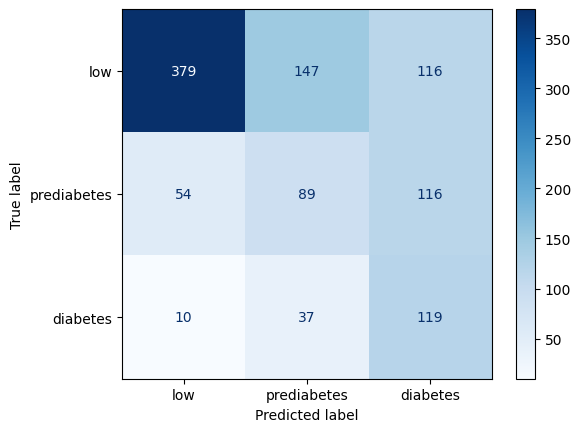

In [8]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

names = ["low", "prediabetes", "diabetes"]
print(classification_report(y_test, y_pred, target_names=names))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=names, cmap="Blues")
plt.show()